# hw2: Решающие деревья

*Спасибо великому курсу великого Евгения Соколова*

### О задании

Задание состоит из двух разделов:
1. В первом разделе вы научитесь применять деревья из sklearn для задачи классификации. Вы посмотрите какие разделяющие поверхности деревья строят для различных датасетов и проанализируете их зависимость от различных гиперпараметров.
2. Во втором разделе вы попробуете реализовать свое решающее дерево и сравните его со стандартное имплементацией из sklearn. Вы также протестируете деревья на более сложных датасетах и сравните различные подходы к кодированию категориальных признаков.

Все данные, на которых будут обучаться модели, вы можете найти на диске.

### Оценивание и штрафы
Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 10 баллов. Неэффективная и/или неоригинальная реализация кода может негативно отразиться на оценке.

### Формат сдачи
Заполненный ноутбук ```hw2-trees.ipynb``` и модуль с реализованными функциями и классами ```hw2code.py``` необходимо загрузить на свой Github. Затем нужно оставить комментарий в Google-таблице с оценками в столбце <<hw2>> в строке со своей фамилией о том, что вы выполнили работу с указанием ника на Kaggle. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from matplotlib.colors import Colormap, ListedColormap
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
sns.set(style='whitegrid')

import warnings
warnings.filterwarnings('ignore')

# 1. Решающие деревья. Визуализация.

В этой части мы рассмотрим два простых двумерных датасета сделанных с помощью `make_moons`, `make_circles` и посмотрим как ведет себя разделяющая поверхность в зависимости от различных гиперпараметров.

In [2]:
from sklearn.datasets import make_moons, make_circles, make_classification
datasets = [
    make_circles(noise=0.2, factor=0.5, random_state=42),
    make_moons(noise=0.2, random_state=42),
    make_classification(n_classes=3, n_clusters_per_class=1, n_features=2, class_sep=.8, random_state=3,
                        n_redundant=0, )
]

In [3]:
palette = sns.color_palette(n_colors=3)
cmap = ListedColormap(palette)

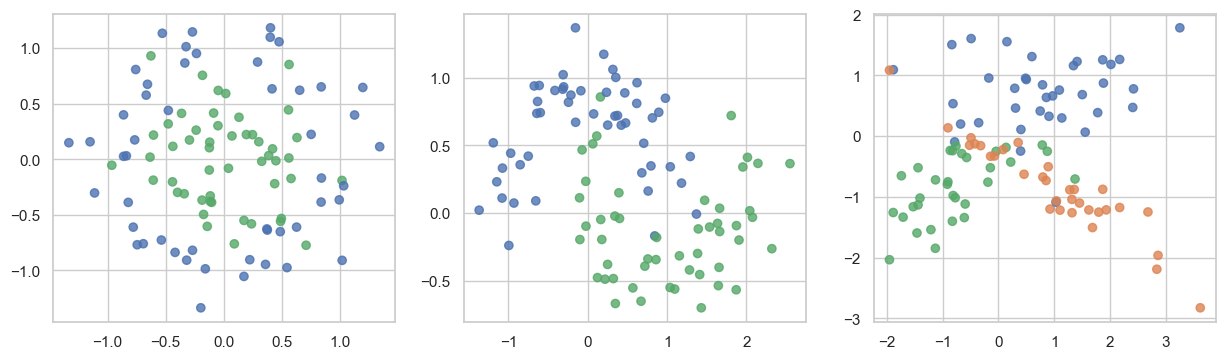

In [4]:
plt.figure(figsize=(15, 4))
for i, (x, y) in enumerate(datasets):
    plt.subplot(1, 3, i + 1)
    plt.scatter(x[:, 0], x[:, 1], c=y, cmap=cmap, alpha=.8)
plt.show()

__Задание 1. (1 балл)__

Для каждого датасета обучите решающее дерево с параметрами по умолчанию, предварительно разбив выборку на обучающую и тестовую. Постройте разделящие поверхности (для этого воспользуйтесь функцией `plot_surface`, пример ниже). Посчитайте accuracy на обучающей и тестовой выборках. Сильно ли деревья переобучились?

In [5]:
def plot_surface(clf, X, y):
    plot_step = 0.03
    palette = sns.color_palette(n_colors=len(np.unique(y)))
    cmap = ListedColormap(palette)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step),
                         np.arange(y_min, y_max, plot_step))
    plt.tight_layout(h_pad=0.5, w_pad=0.5, pad=2.5)

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    cs = plt.contourf(xx, yy, Z, cmap=cmap, alpha=0.3)

    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, alpha=.7,
                edgecolors=np.array(palette)[y], linewidths=2)

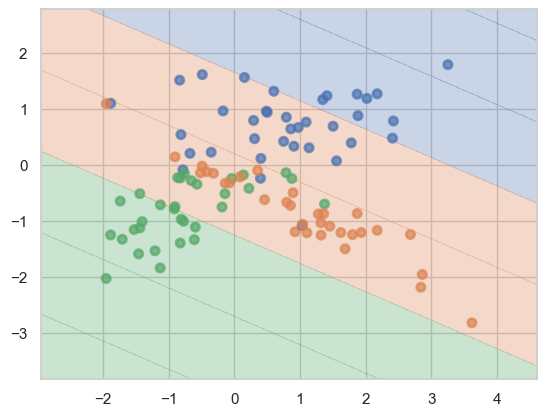

In [6]:
# Пример:
from sklearn.linear_model import LinearRegression
X, y = datasets[2]
lr  = LinearRegression().fit(X, y)
plot_surface(lr, X, y)
plt.show()

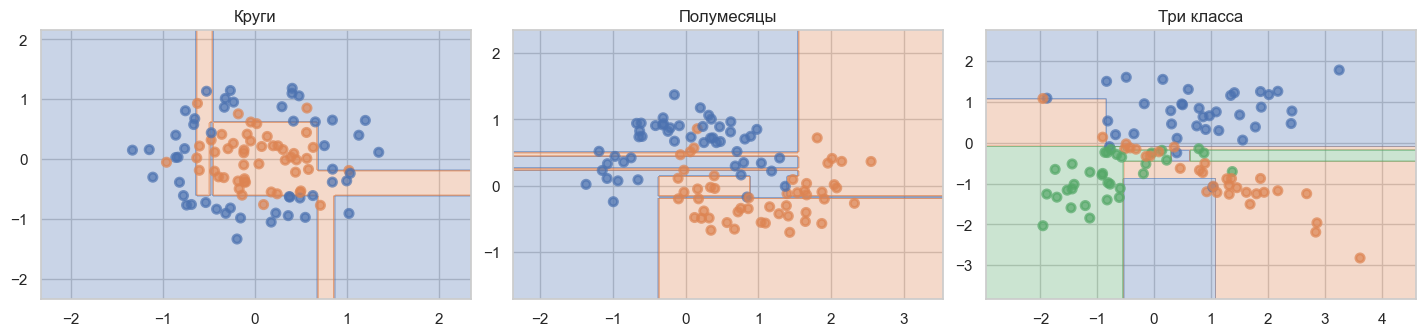

,Accuracy train,Accuracy test
Круги,1.0,0.700
Полумесяцы,1.0,0.933
Три класса,1.0,0.667


In [7]:
names = ['Круги', 'Полумесяцы', 'Три класса']
splits = [train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
          for X, y in datasets]

scores = []
plt.figure(figsize=(15, 4))
for i, (name, split) in enumerate(zip(names, splits)):
    X_train, X_test, y_train, y_test = split
    tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
    plt.subplot(1, 3, i + 1)
    plot_surface(tree, *datasets[i])
    plt.title(name)
    scores.append([tree.score(X_train, y_train), tree.score(X_test, y_test)])
plt.show()
pd.DataFrame(scores, index=names, columns=['Accuracy train', 'Accuracy test']).round(3)

На обучении все три дерева дали accuracy 1. На тесте сильнее всего просело качество на трёх классах (0.667) и кругах (0.700). На полумесяцах переобучение слабее (0.933)

__Задание 2. (1.5 балла)__

Попробуйте перебрать несколько параметров для регуляризации (напр. `max_depth`, `min_samples_leaf`). Для каждого набора гиперпараметров постройте разделяющую поверхность, выведите обучающую и тестовую ошибки. Можно делать кросс-валидацию или просто разбиение на трейн и тест, главное делайте каждый раз одинаковое разбиение, чтобы можно было корректно сравнивать (помните же, что итоговое дерево сильно зависит от небольшого изменения обучающей выборки?). Проследите как меняется разделяющая поверхность и обобщающая способность. Почему так происходит, одинаково ли изменение для разных датасетов?

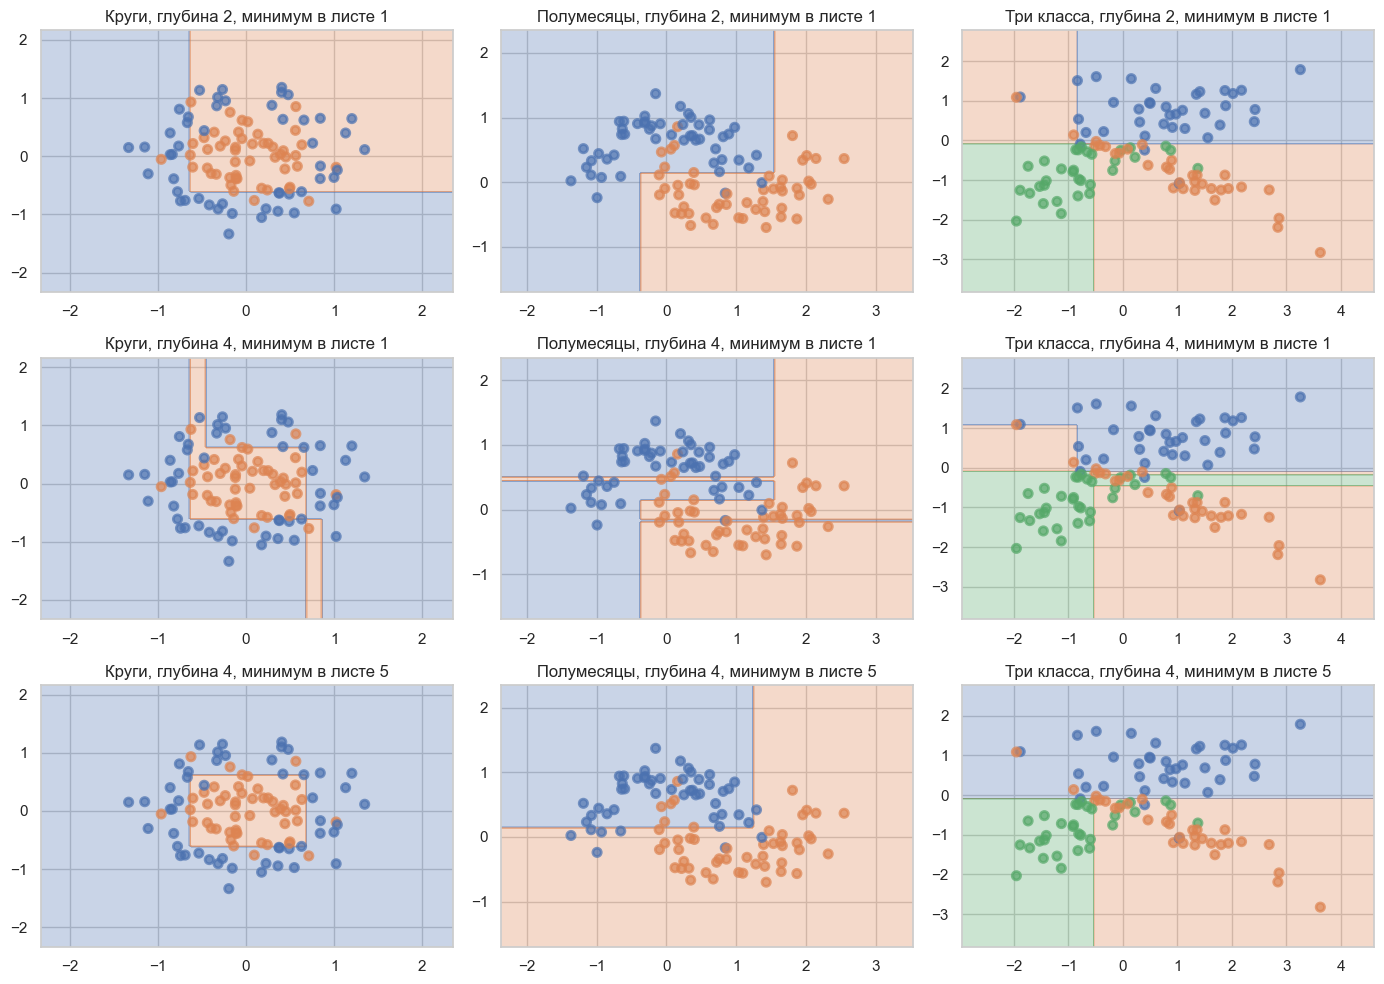

,Датасет,max_depth,min_samples_leaf,Ошибка train,Ошибка test
0,Круги,2,1,0.186,0.367
1,Полумесяцы,2,1,0.071,0.067
2,Три класса,2,1,0.100,0.167
3,Круги,4,1,0.029,0.200
4,Полумесяцы,4,1,0.029,0.067
5,Три класса,4,1,0.029,0.267
6,Круги,4,5,0.057,0.167
7,Полумесяцы,4,5,0.100,0.200
8,Три класса,4,5,0.114,0.167


In [8]:
settings = [(2, 1), (4, 1), (4, 5)]
errors = []
fig, axes = plt.subplots(len(settings), len(names), figsize=(14, 10))
for row, (depth, leaf) in enumerate(settings):
    for i, (name, split) in enumerate(zip(names, splits)):
        X_train, X_test, y_train, y_test = split
        tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=42)
        tree.fit(X_train, y_train)
        plt.sca(axes[row, i])
        plot_surface(tree, *datasets[i])
        plt.title(f'{name}, глубина {depth}, минимум в листе {leaf}')
        errors.append([name, depth, leaf, 1 - tree.score(X_train, y_train),
                       1 - tree.score(X_test, y_test)])
plt.tight_layout()
plt.show()
pd.DataFrame(errors, columns=['Датасет', 'max_depth', 'min_samples_leaf',
                              'Ошибка train', 'Ошибка test']).round(3)

При глубине 2 дерево делит плоскость максимум на четыре прямоугольника. Для кругов этого мало. При увеличении глубины до 4 тестовая ошибка падает с 0.367 до 0.200, а минимум в пять объектов в листе убирает мелкие области и снижает ошибку до 0.167. На полумесяцах тот же минимум повышает ошибку с 0.067 до 0.200. Для трёх классов глубины 2 уже хватает, поскольку дополнительные разбиения снижают ошибку на обучении, но повышают её на тесте

# 2. Решающие деревья своими руками

В этой части вам нужно реализовать свой класс для обучения решающего дерева в задаче бинарной классификации с возможностью обработки вещественных и категориальных признаков.

__Задание 3. (1.5 балл)__

Реализуйте функцию find_best_split из модуля hw2code.py

__Задание 4. (0.5 балла)__

Загрузите таблицу students.csv (это немного преобразованный датасет [User Knowledge](https://archive.ics.uci.edu/ml/datasets/User+Knowledge+Modeling)). В ней признаки объекта записаны в первых пяти столбцах, а в последнем записана целевая переменная (класс: 0 или 1). Постройте на одном изображении пять кривых "порог — значение критерия Джини" для всех пяти признаков. Отдельно визуализируйте scatter-графики "значение признака — класс" для всех пяти признаков.

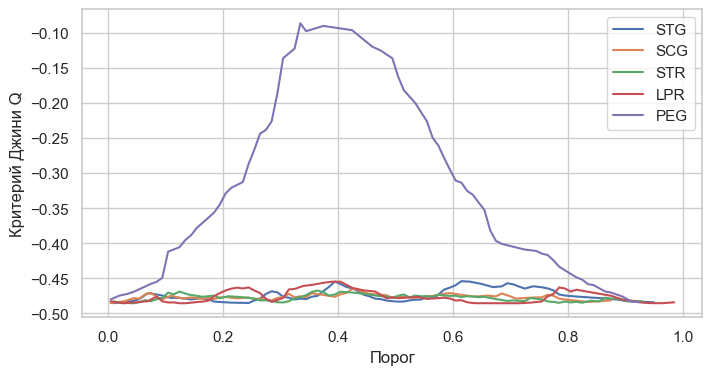

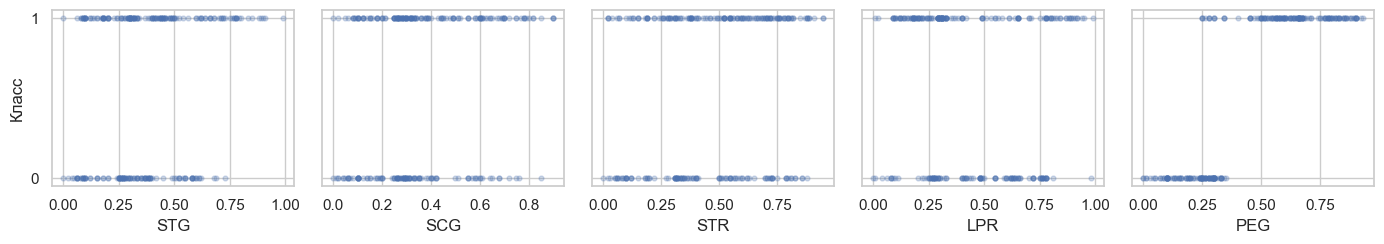

,Лучший порог,Q
STG,0.615,-0.4540
SCG,0.425,-0.4650
STR,0.365,-0.4673
LPR,0.390,-0.4547
PEG,0.335,-0.0861


In [9]:
from hw2code import find_best_split

students = pd.read_csv('datasets/students.csv')
features = students.columns[:-1]
target = students.iloc[:, -1]
best_splits = []
plt.figure(figsize=(8, 4))
for feature in features:
    thresholds, ginis, threshold, gini = find_best_split(students[feature], target)
    plt.plot(thresholds, ginis, label=feature)
    best_splits.append([threshold, gini])
plt.xlabel('Порог')
plt.ylabel('Критерий Джини Q')
plt.legend()
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(14, 2.6), sharey=True)
for ax, feature in zip(axes, features):
    ax.scatter(students[feature], target, alpha=0.25, s=12)
    ax.set_xlabel(feature)
axes[0].set(ylabel='Класс', yticks=[0, 1])
plt.tight_layout()
plt.show()
pd.DataFrame(best_splits, index=features, columns=['Лучший порог', 'Q']).round(4)

__Задание 5. (0.5 балла)__

Исходя из кривых значений критерия Джини, по какому признаку нужно производить деление выборки на два поддерева? Согласуется ли этот результат с визуальной оценкой scatter-графиков? Как бы охарактеризовали вид кривой для "хороших" признаков, по которым выборка делится почти идеально? Чем отличаются кривые для признаков, по которым деление практически невозможно?

Лучше всего делить по PEG при пороге 0.335. Здесь Q достигает −0.0861. На диаграмме рассеяния почти все объекты слева от порога относятся к одному классу, справа – к другому. У сильного признака есть выраженный максимум Q вблизи нуля. У слабых признаков кривая почти плоская и остаётся близкой к значению до разбиения

__Задание 6. (1.5 балла).__

Разберитесь с уже написанным кодом в классе DecisionTree модуля hw2code.py. Найдите ошибки в реализации метода \_fit_node. Напишите функцию \_predict_node.

 Построение дерева осуществляется согласно базовому жадному алгоритму, предложенному в лекции. Выбор лучшего разбиения необходимо производить по критерию Джини. Критерий останова: все объекты в листе относятся к одному классу или ни по одному признаку нельзя разбить выборку. Ответ в листе: наиболее часто встречающийся класс в листе. Для категориальных признаков выполняется преобразование, описанное в лекции в разделе «Учет категориальных признаков».

__Задание 7. (0.5 балла)__

Протестируйте свое решающее дерево на датасете [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom). Вам нужно скачать таблицу agaricus-lepiota.data (лежит на гитхабе вместе с заданием), прочитать ее с помощью pandas, применить к каждому столбцу LabelEncoder (из sklearn), чтобы преобразовать строковые имена категорий в натуральные числа. Первый столбец — это целевая переменная (e — edible, p — poisonous) Мы будем измерять качество с помощью accuracy, так что нам не очень важно, что будет классом 1, а что — классом 0. Обучите решающее дерево на половине случайно выбранных объектов (признаки в датасете категориальные) и сделайте предсказания для оставшейся половины. Вычислите accuracy.

У вас должно получиться значение accuracy, равное единице (или очень близкое к единице), и не очень глубокое дерево.

In [10]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.metrics import accuracy_score, make_scorer
from sklearn.model_selection import cross_val_score
from hw2code import DecisionTree

def encode_columns(frame):
    return frame.apply(lambda column: LabelEncoder().fit_transform(column)).to_numpy()

mushrooms = encode_columns(pd.read_csv('datasets/agaricus-lepiota.data', header=None))
X_mush, y_mush = mushrooms[:, 1:], mushrooms[:, 0]
X_train, X_test, y_train, y_test = train_test_split(
    X_mush, y_mush, test_size=0.5, stratify=y_mush, random_state=42)
tree = DecisionTree(['categorical'] * X_mush.shape[1]).fit(X_train, y_train)
print('Accuracy:', accuracy_score(y_test, tree.predict(X_test)))
print('Глубина дерева:', tree.depth_)

Accuracy: 1.0
Глубина дерева: 7


__Задание 8. (бонус, 1 балл)__

Реализуйте в классе DecisionTree поддержку параметров max_depth, min_samples_split и min_samples_leaf по аналогии с DecisionTreeClassifier. Постройте графики зависимости качества предсказания в зависимости от этих параметров для набора данных tic-tac-toe (см. следующий пункт).

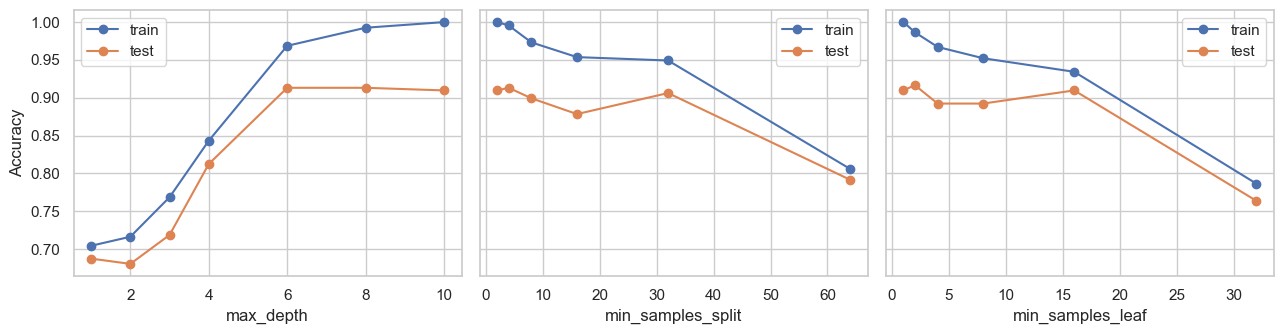

In [11]:
tic = encode_columns(pd.read_csv('datasets/tic-tac-toe-endgame.csv'))
X_tic, y_tic = tic[:, :-1], tic[:, -1]
X_train, X_test, y_train, y_test = train_test_split(
    X_tic, y_tic, test_size=0.3, stratify=y_tic, random_state=42)

grid = {'max_depth': [1, 2, 3, 4, 6, 8, 10],
        'min_samples_split': [2, 4, 8, 16, 32, 64],
        'min_samples_leaf': [1, 2, 4, 8, 16, 32]}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, (param, values) in zip(axes, grid.items()):
    train_scores, test_scores = [], []
    for value in values:
        tree = DecisionTree(['categorical'] * X_tic.shape[1], **{param: value})
        tree.fit(X_train, y_train)
        train_scores.append(tree.score(X_train, y_train))
        test_scores.append(tree.score(X_test, y_test))
    ax.plot(values, train_scores, 'o-', label='train')
    ax.plot(values, test_scores, 'o-', label='test')
    ax.set_xlabel(param)
    ax.legend()
axes[0].set_ylabel('Accuracy')
plt.tight_layout()
plt.show()

__Задание 9. (2 балла)__

Загрузите следующие наборы данных (напомним, что pandas умеет загружать файлы по url, в нашем случае это файл \*.data), предварительно ознакомившись с описанием признаков и целевой переменной в каждом из них (она записаны в Data Folder, в файле *.names): 
* [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom) (загрузили в предыдущем пункте, классы записаны в нулевом столбце)
* [tic-tac-toe](https://archive.ics.uci.edu/ml/datasets/Tic-Tac-Toe+Endgame) (классы записаны в последнем столбце, датасет лежит на гитхабе вместе с заданием)
* [cars](https://archive.ics.uci.edu/ml/datasets/Car+Evaluation) (классы записаны в последнем столбце, считаем что unacc, acc — это класс 0, good, vgood — класс 1)
* [nursery](https://archive.ics.uci.edu/ml/datasets/Nursery) (классы записаны в последнем столбце, считаем, что not_recom и recommend — класс 0, very_recom, priority, spec_prior — класс 1).

Закодируйте категориальные признаки, использовав LabelEncoder. С помощью cross_val_score (cv=10) оцените accuracy на каждом из этих наборов данных следующих алгоритмов:
* DecisionTree, считающий все признаки вещественными
* DecisionTree, считающий все признаки категориальными
* DecisionTree, считающий все признаки вещественными + one-hot-encoding всех признаков
* DecisionTreeClassifier из sklearn. Запишите результат в pd.DataFrame (по строкам — наборы данных, по столбцам — алгоритмы).

Рекомендации:
* Чтобы cross_val_score вычисляла точность, нужно передать scoring=make_scorer(accuracy_score), обе фукнции из sklearn.metrics.
* Если вам позволяет память (а она скорее всего позволяет), указывайте параметр sparse=False в OneHotEncoder (если вы, конечно, используете его). Иначе вам придется добиваться того, чтобы ваша реализация дерева умела работать с разреженными матрицами (что тоже, в целом, не очень сложно).

In [12]:
cars = pd.read_csv('datasets/car.data', header=None)
nursery = pd.read_csv('datasets/nursery.data', header=None)
data = {
    'mushrooms': (X_mush, y_mush),
    'tic-tac-toe': (X_tic, y_tic),
    'cars': (encode_columns(cars.iloc[:, :-1]), cars.iloc[:, -1].isin(['good', 'vgood']).astype(int)),
    'nursery': (encode_columns(nursery.iloc[:, :-1]),
                nursery.iloc[:, -1].isin(['very_recom', 'priority', 'spec_prior']).astype(int))
}

results = {}
for name, (X, y) in data.items():
    X_onehot = OneHotEncoder(sparse_output=False).fit_transform(X)
    models = {
        'Вещественные': (DecisionTree(['real'] * X.shape[1]), X),
        'Категориальные': (DecisionTree(['categorical'] * X.shape[1]), X),
        'One-hot': (DecisionTree(['real'] * X_onehot.shape[1]), X_onehot),
        'sklearn': (DecisionTreeClassifier(random_state=42), X)
    }
    results[name] = {
        label: cross_val_score(model, values, y, cv=10, scoring=make_scorer(accuracy_score),
                               error_score='raise').mean()
        for label, (model, values) in models.items()
    }
pd.DataFrame.from_dict(results, orient='index').round(4)

,Вещественные,Категориальные,One-hot,sklearn
mushrooms,0.9656,0.9823,0.9673,0.9604
tic-tac-toe,0.7696,0.8217,0.8175,0.7717
cars,0.9450,0.8804,0.8289,0.9427
nursery,0.9997,0.9998,0.9995,0.9997


__Задание 10. (1 балла)__

Проанализируйте результаты эксперимента. 
Одинаково ли для разных наборов данных ранжируются алгоритмы? 
Порассуждайте, почему так происходит. 

Обратите внимание на значение признаков в разных наборах данных. 
Присутствует ли в результатах какая-то компонента случайности? 
Можно ли повлиять на нее и улушить работу алгоритмов?

На mushrooms и tic-tac-toe лучше дерево с категориальными признаками. Цвет гриба и символ в клетке не имеют естественного порядка. Дерево может объединить категории с близкими долями класса 1, а числовой порог разделяет их только по порядку кодов. На cars первое место у дерева с числовыми порогами (0.9450). Например, коды числа дверей сохраняют порядок, и один порог сразу объединяет соседние значения. На nursery все варианты дают выше 0.999, поэтому разница мала

На результат влияют состав фолдов и выбор между равноценными разбиениями. В sklearn он зависит от random_state. Фиксация seed делает результат воспроизводимым. Для порядковых признаков можно задать коды по смыслу и проверить выигрыш на одинаковых разбиениях. Устойчивость результата можно оценить повторной стратифицированной кросс-валидацией

Вставьте что угодно, описывающее ваши впечатления от этого задания:

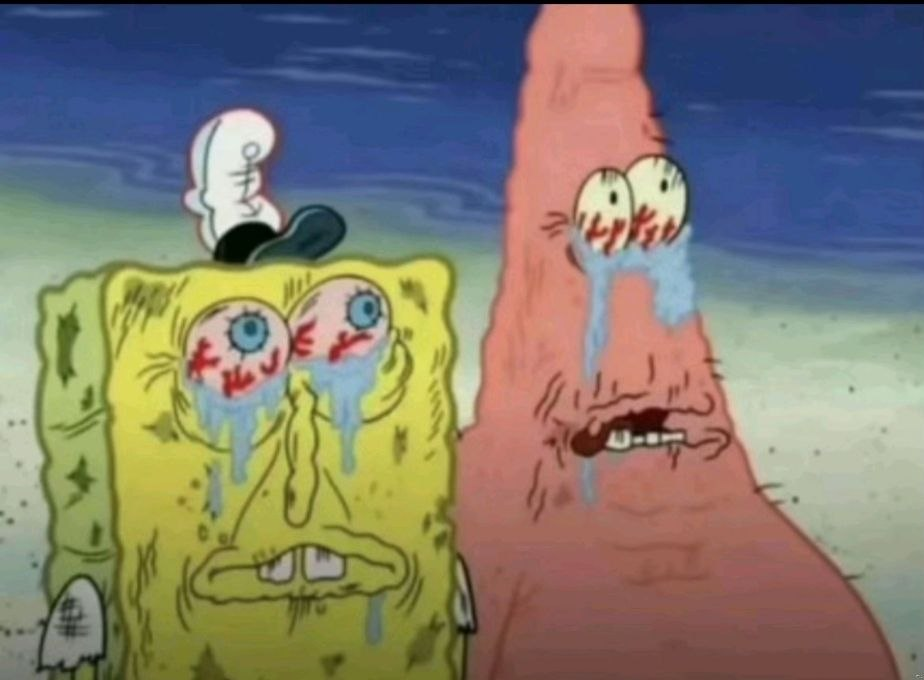

**'(=^・ω・^=)**